# 06 · Decision Framework

The guide. This notebook consolidates the measured evidence from notebooks 01–05 into a
set of defaults you can apply, and the one figure that captures the whole trade-off:
**memory vs quality**.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


## The evidence, gathered

Every number below was produced and saved by an earlier notebook — nothing here is
asserted from memory.

In [2]:
import json

from src.artifacts import DATA_DIR

def load(name):
    return json.loads((DATA_DIR / f"{name}.json").read_text())

r01, r02, r03, r04, r05 = (load(f"0{i}_results") for i in range(1, 6))

evidence = {
    "int8 reconstruction error (real matrix)": f"{r02['relerr_int8_absmax']:.2%}",
    "int8 downstream logit cosine": f"{r05['quality'][1]['logit_cosine']:.5f}",
    "int8 perplexity vs fp32": f"{r05['quality'][1]['perplexity']:.1f} vs {r05['quality'][0]['perplexity']:.1f}",
    "outlier: ordinary codes used (per-tensor)": f"{r03['distinct_codes_ordinary_per_tensor']} / 256",
    "outlier: per-tensor vs per-channel error": f"{r03['ratio_int8']:.0f}x worse",
    "clipping: error before vs after": f"{r04['clip_no_clip_error']:.1%} -> {r04['clip_best_error']:.1%}",
    "activation per-row vs weight per-row": f"{r04['activation_per_row_err']:.1%} vs {r04['weight_per_row_err']:.1%}",
    "int4 per-channel vs per-tensor perplexity": f"{r05['quality'][2]['perplexity']:.0f} vs {r05['quality'][3]['perplexity']:.0f}",
    "memory: int8 / int4": f"{r05['memory_ratio_int8']:.2f}x / {r05['memory_ratio_int4']:.2f}x",
}
for k, v in evidence.items():
    print(f"- {k}: {v}")

- int8 reconstruction error (real matrix): 1.34%
- int8 downstream logit cosine: 0.99990
- int8 perplexity vs fp32: 188.5 vs 184.8
- outlier: ordinary codes used (per-tensor): 6 / 256
- outlier: per-tensor vs per-channel error: 16x worse
- clipping: error before vs after: 21.5% -> 1.0%
- activation per-row vs weight per-row: 18.4% vs 1.7%
- int4 per-channel vs per-tensor perplexity: 534 vs 6341
- memory: int8 / int4: 0.25x / 0.13x


## The trade-off, in one figure

Memory on the x-axis, perplexity (lower is better) on the y-axis. fp32 and int8 sit
together at good quality; int4 per-channel buys more memory at a real quality cost; int4
*naive* per-tensor is dominated — same memory, far worse quality. The job of GPTQ/AWQ is to
pull the int4 point down toward int8.

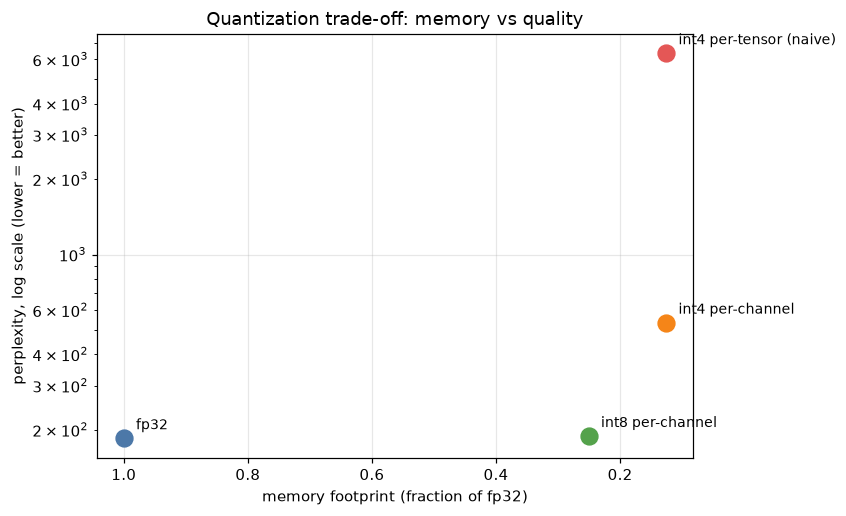

In [3]:
q = r05["quality"]
mem_ratio = {32: 1.0, 8: r05["memory_ratio_int8"], 4: r05["memory_ratio_int4"]}
colors = {"fp32": "#4C78A8", "int8 per-channel": "#54A24B",
          "int4 per-channel": "#F58518", "int4 per-tensor (naive)": "#E45756"}

fig, ax = plt.subplots(figsize=(7, 5))
for row in q:
    x = mem_ratio[row["bits"]]
    ax.scatter(x, row["perplexity"], s=120, color=colors[row["config"]], zorder=3)
    ax.annotate(row["config"], (x, row["perplexity"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("memory footprint (fraction of fp32)")
ax.set_ylabel("perplexity, log scale (lower = better)")
ax.set_title("Quantization trade-off: memory vs quality")
ax.invert_xaxis()
save_figure(fig, "06_tradeoff")
plt.show()

## The defaults

1. **Quantize weights to int8 almost always.** It is nearly free with per-channel scales —
   a fraction of a percent of reconstruction error and essentially unchanged behavior.
2. **Prefer per-channel over per-tensor, always.** It is how outliers are contained; it is
   the single biggest quality lever, for little cost.
3. **Go to int4 when memory demands it**, with per-channel scales and outlier handling
   (clipping, or keeping sensitive layers like embeddings higher precision), and expect a
   small but real, measurable quality cost. For the best int4, reach for GPTQ/AWQ.
4. **Be cautious with activation quantization.** Activation outliers are shared across
   tokens, so a per-token scale cannot contain them — this is why weight-only is the common
   default.
5. **Always measure both reconstruction error and downstream quality.** A small
   reconstruction error is necessary but not sufficient; perplexity/accuracy is the verdict.
6. **Combine with LoRA (QLoRA)** when you need to fine-tune a large model in limited memory:
   quantize the frozen base (this project) and train small LoRA adapters on top (`lora_101`).

In [4]:
def recommend(memory_budget_fraction):
    if memory_budget_fraction >= 0.25:
        return "int8 per-channel — nearly free, do it by default"
    if memory_budget_fraction >= 0.125:
        return "int4 per-channel + outlier handling; keep embeddings higher precision; expect a quality cost"
    return "sub-4-bit / calibration-based (GPTQ, AWQ) territory — see extensions"

examples = {f"{b:.3g}x budget": recommend(b) for b in (0.5, 0.25, 0.125, 0.06)}
for budget, rec in examples.items():
    print(f"{budget:>12}: {rec}")

 0.5x budget: int8 per-channel — nearly free, do it by default
0.25x budget: int8 per-channel — nearly free, do it by default
0.125x budget: int4 per-channel + outlier handling; keep embeddings higher precision; expect a quality cost
0.06x budget: sub-4-bit / calibration-based (GPTQ, AWQ) territory — see extensions


## Takeaway

The lesson is two-sided and exact: **most of the precision in a model is genuinely wasted —
you can throw away three quarters of every number and barely notice — but the small fraction
that is not wasted, the outliers, will destroy a naive quantizer.** The entire art of modern
quantization is telling those two apart: per-channel scales, outlier handling, and always
measuring what you actually changed.

In [5]:
results = {"evidence": evidence, "defaults_examples": examples}
path = save_json(results, "06_results")
print("saved", path)
results

saved /workspaces/quantization_101/outputs/data/06_results.json


{'evidence': {'int8 reconstruction error (real matrix)': '1.34%',
  'int8 downstream logit cosine': '0.99990',
  'int8 perplexity vs fp32': '188.5 vs 184.8',
  'outlier: ordinary codes used (per-tensor)': '6 / 256',
  'outlier: per-tensor vs per-channel error': '16x worse',
  'clipping: error before vs after': '21.5% -> 1.0%',
  'activation per-row vs weight per-row': '18.4% vs 1.7%',
  'int4 per-channel vs per-tensor perplexity': '534 vs 6341',
  'memory: int8 / int4': '0.25x / 0.13x'},
 'defaults_examples': {'0.5x budget': 'int8 per-channel — nearly free, do it by default',
  '0.25x budget': 'int8 per-channel — nearly free, do it by default',
  '0.125x budget': 'int4 per-channel + outlier handling; keep embeddings higher precision; expect a quality cost',
  '0.06x budget': 'sub-4-bit / calibration-based (GPTQ, AWQ) territory — see extensions'}}